In [1]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
from helper import plot_ct_density

blue_red_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)



plt.rcParams["axes.unicode_minus"] = False

In [2]:
figure_save_path = "../results/Fig_1_figures"
os.makedirs(figure_save_path, exist_ok=True)

## Fig. 1b

In [3]:
lineage_data = sc.read("../data/WL_lineage_min.h5ad")

In [4]:
lineage_data

AnnData object with n_obs × n_vars = 73419 × 18081
    obs: 'Sample', 'Sample_ID', 'Status', 'Age', 'Area', 'Passage', 'Protocol', 'Age_status', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'mt_outlier', 'Condition', 'Protocol_Condition', 'epithelial_score', 'mesenchymal_score', 'immune_score', 'endothelial_score', 'proliferating_score', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.60', 'leiden_res_0.70', 'leiden_res_0.80', 'leiden_res_0.90', 'lineage'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'dendrogram_leiden_res_0.10', 'dendrogram_leiden_res_

In [5]:
del lineage_data.layers['counts']
del lineage_data.layers['scaled']


In [8]:
del lineage_data.obsm['X_tsne']

In [9]:
cols_to_drop = [
    'epithelial_score', 'mesenchymal_score', 'immune_score',
    'endothelial_score', 'proliferating_score',
    'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30',
    'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.60',
    'leiden_res_0.70', 'leiden_res_0.80', 'leiden_res_0.90'
]

lineage_data.obs = lineage_data.obs.drop(columns=cols_to_drop)

In [10]:
lineage_data.write("../data/WL_lineage_min.h5ad")

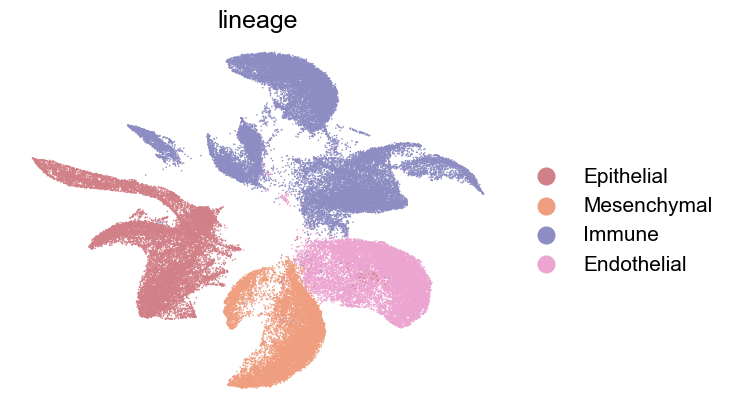

In [4]:
with plt.rc_context({
    'font.size': 15,
    'legend.fontsize': 15,
    'legend.markerscale': 2
}):
    sc.pl.umap(lineage_data, color='lineage', frameon=False, size=5)

## Fig. 1c

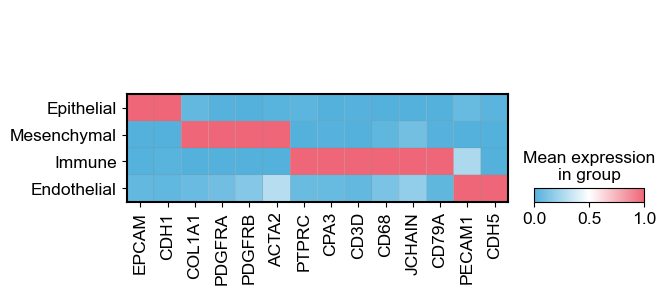

In [5]:
lineage_marker_dict = {
    "Epithelial": ['EPCAM', 'CDH1'],
    "Mesenchymal": ['COL1A1', 'PDGFRA', 'PDGFRB', 'ACTA2'],
    "Immune": ['PTPRC', 'CPA3', 'CD3D', 'CD68', 'JCHAIN', 'CD79A'],
    "Endothelial": ['PECAM1', 'CDH5']
}

lineage_markers_list = []
for category in lineage_marker_dict.values():
    lineage_markers_list.extend(category)

with plt.rc_context({'font.size': 15, 'figure.figsize': (4, 3)}):
    sc.pl.matrixplot(
        lineage_data,
        var_names=lineage_markers_list,
        groupby='lineage',
        standard_scale='var',
        cmap=blue_red_cmap,
    )

## Fig. 1d

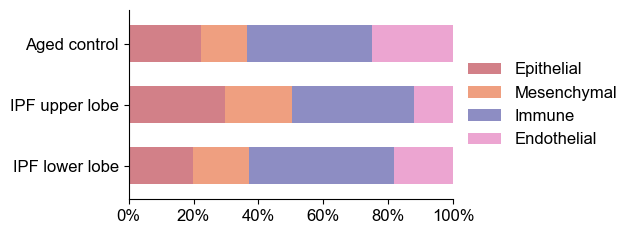

In [6]:
with plt.rc_context({'font.size': 12, 'legend.fontsize': 12}):
    fig, df  = plot_ct_density(lineage_data, ct_key='lineage', group_key='Condition', figsize=(6.5, 2.5), title="")
    fig.savefig(f'{figure_save_path}/WL_linege_proportion.pdf', bbox_inches='tight')
    plt.show()

## Fig. 1e 

In [13]:
adata = sc.read("../data/WL_fibroblasts_min.h5ad")
adata.obs['annotation'] = pd.Categorical(
    adata.obs['annotation'],
    categories=['Alveolar', 'Adventitial', 'Inflammatory', 'SMC', 'CTHRC1+', 'Peribronchial']
    )
adata.uns['annotation_colors'] = ['#3CA5D1', '#8D8DC3',  '#EF9F80',  '#D28088', '#FF5919', '#58A456']

In [14]:
del adata.layers['counts']
del adata.layers['scaled']

adata.write("../data/WL_fibroblasts_min.h5ad")

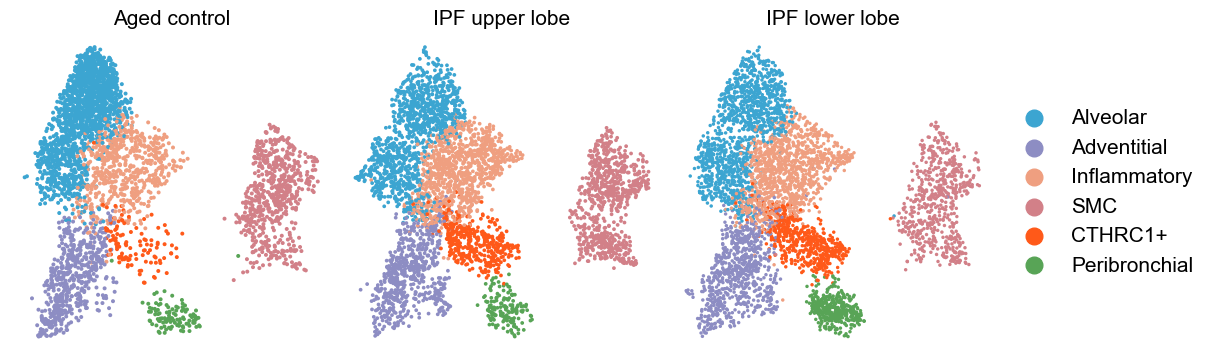

In [9]:
conditions = ['Aged control', 'IPF upper lobe', 'IPF lower lobe']

fig, axes = plt.subplots(1, len(conditions), figsize=(12, 3.5), constrained_layout=True)

with plt.rc_context({
    'font.size': 15,
    'axes.titlesize': 15,
    'legend.fontsize': 15,
    'legend.markerscale': 2
}):
    for i, (ax, c) in enumerate(zip(axes, conditions)):
        adata_c = adata[adata.obs['Condition'] == c]
        sc.pl.umap(
            adata_c,
            color=['annotation'],
            frameon=False,
            title=c,
            ax=ax,
            show=False,
            legend_loc='right margin' if i == len(conditions) - 1 else None,
        )

    fig.savefig(f'{figure_save_path}/WL_fibroblasts_umap_by_condition.pdf', bbox_inches='tight')
    plt.show()

## Fig. 1f

In [10]:
fibroblast_markers = {
    "Alveolar": ["NPNT", "CES1", "WNT2", "TCF21", "INMT", "FIBIN",
                 "AOC3", "GPM6B", "SCN7A", "FMO2", "CYP4B1", "LIMCH1",
                 "FGFR4", "ITGA8", "RARRES2", "GPC3"],
        "Adventitial": ["MFAP5", "SCARA5", "PTGIS", "IGFBP6", "SFRP2", "PI16"],
    "Inflamatory": ["CCL2", "CXCL12", "HAS2", "PTGDS"],
    "CTHRC1+": ["CTHRC1", "TGFB1", "POSTN", "COL10A1"],
    "Peribronchial": ["WIF1", "FGF18", "ASPN"],
    "SMC": ["MYH11", "ACTA2", "LMOD1", "MYL9"],
}

fibroblast_markers_list = []
for category in fibroblast_markers.values():
    fibroblast_markers_list.extend(category)

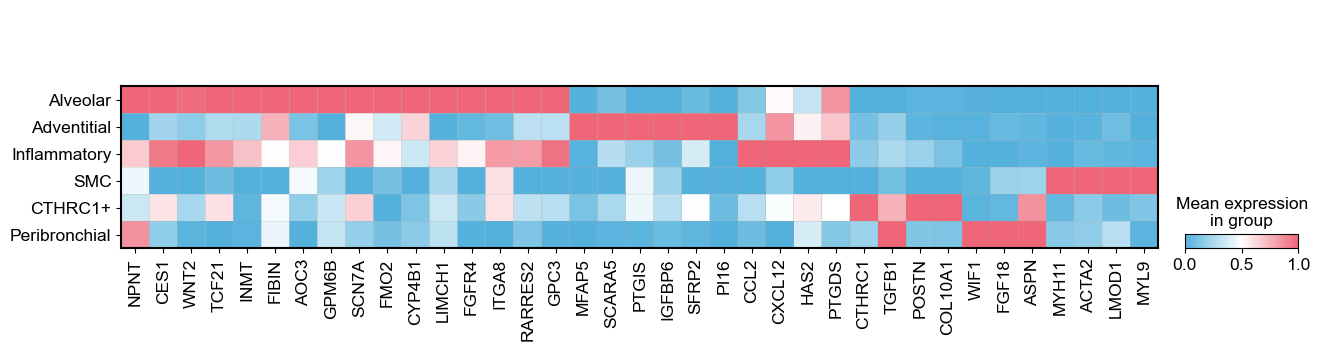

In [11]:
with plt.rc_context({'font.size': 15, 'figure.figsize': (4, 3)}):
    fig = sc.pl.matrixplot(
        adata,
        var_names=fibroblast_markers_list,
        groupby='annotation',
        standard_scale='var',
        cmap=blue_red_cmap,
        linewidths=3,
        return_fig=True
    )
    fig.savefig(f'{figure_save_path}/WL_fibroblasts_heatmap.pdf', bbox_inches='tight')
    plt.show()

## Fig. 1g

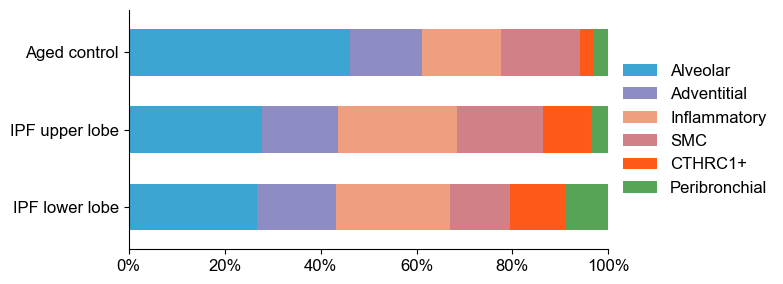

In [12]:
with plt.rc_context({'font.size': 12, 'legend.fontsize': 12}):
    fig, df  = plot_ct_density(adata, ct_key='annotation', group_key='Condition', figsize=(8, 3), title="")
    fig.savefig(f'{figure_save_path}/WL_fibroblasts_proportion.pdf', bbox_inches='tight')
    plt.show()